# Freight Capstone: Network + Base Selection + Temporal Validation
## เลือกฐานรับจ้างขนส่งภายใต้จำนวนฐานจำกัด
Notebook ภาษาไทย: ข้อมูล → เลือกสินค้า → Network → validation → Model A/B → ตรวจย้อนหลัง → กราฟและข้อสรุป

**สถานะ:** ผลเพื่อศึกษาความเป็นไปได้ ไม่ใช่คำแนะนำลงทุน ใช้ข้อมูลหลัก ม.ค.–เม.ย. 2569 เทียบปี 2568 เฉพาะเดือนร่วม

### วิธีใช้
1. รันเซลล์ bootstrap ด้านล่าง: ดาวน์โหลด CSV สองปีจาก สนข. และตรวจ SHA-256 (ถ้าดาวน์โหลดไม่ได้ เช่น SSL error ให้โหลดไฟล์ด้วย browser/curl ไปไว้ที่ `data/` แล้วรันใหม่ hash ยังถูกตรวจ)
2. Run All ตามลำดับ ผลที่คำนวณจะอยู่ `results/`
3. โหมดเต็มใช้ 100 seeds และ null 100 ครั้งต่อแบบ ใช้เวลาไม่กี่นาที
4. ส่วน 11 คือการตรวจเพิ่มตามมาตรฐานรายวิชา (บทที่ 1–12) ผลในส่วน 1–9 ไม่ถูกแก้

ตัวเลขไม่ถูกเขียนทับให้ตรงรายงานเดิม ถ้าข้อมูล/เวอร์ชันไลบรารีเปลี่ยน ผล partition และคำตอบที่คะแนนเสมอกันอาจเปลี่ยนได้ ให้ตรวจผลจริงก่อนนำไปใส่สไลด์

## เปิดจาก GitHub/Colab
เซลล์ถัดไปดาวน์โหลดข้อมูลดิบสองปีจาก สนข. (รวมประมาณ 133 MB) และไฟล์พิกัด/ระยะจาก repo โดยตรวจ hash กับชุดที่ใช้รัน ผลที่บันทึกไว้เป็นผลจากข้อมูลเดิม การดาวน์โหลดขึ้นกับบริการต้นทาง

เซลล์ bootstrap เพิ่มสำหรับ GitHub; ผลการวิเคราะห์ด้านล่างรันครบแล้วบนข้อมูลในเครื่อง ไม่ได้ยืนยันการดาวน์โหลดต้นทางบน Colab หาก source เปลี่ยนจะหยุดเพื่อไม่ใช้ข้อมูลต่างชุดโดยไม่รู้ตัว

In [1]:
# GitHub / Colab bootstrap: official source CSVs + small reference files
from pathlib import Path
import urllib.request, hashlib, json
root_url = 'https://raw.githubusercontent.com/Pornphrom/MADT7202_capstone_freight/main/'
data = Path('data'); data.mkdir(exist_ok=True)
sources = {
 'otp_69_01_69.csv': 'https://otp.gdcatalog.go.th/dataset/91038df9-854e-442d-8408-c54032daf506/resource/ac3db7c7-c4f1-4ca8-93b9-62d36d832f97/download/otp_69_01_69.csv',
 'otp_69_01_68.csv': 'https://otp.gdcatalog.go.th/dataset/91038df9-854e-442d-8408-c54032daf506/resource/5f502b31-3c49-4faa-9a02-34a92abdb863/download/otp_69_01_68.csv',
 'province_coordinates_used.csv': root_url+'data/province_coordinates_used.csv',
 'straight_line_distance_km.csv': root_url+'data/straight_line_distance_km.csv',
}
expected = {'otp_69_01_68.csv': '86373d5a61b5ebc81ddaa547fa7bbdd8bb12253624c000a3d469b4ddc31aa3ca', 'otp_69_01_69.csv': 'ee38ebd5ef670489f321a93d2c32e94e1f7ed57d6e5e76a5bcb14fb72963bd82', 'province_coordinates_used.csv': '6082b1b14a740130455e75c3596358f62af6549b60d31a81b16c8a69bed68c48', 'straight_line_distance_km.csv': 'ce2f1e3e656f23435d6b2b5562909c9d2fe6ee49fca70325adf742d92019ced1'}
for name,url in sources.items():
    target=data/name
    if not target.exists():
        print('Downloading',name)
        partial=data/(name+'.part')
        try: urllib.request.urlretrieve(url,partial)
        except OSError as e: raise SystemExit(f'Download failed ({e}). Save {url} as data/{name} manually (browser or curl -L), then re-run; the hash check still applies.')
        partial.replace(target)
    actual=hashlib.sha256(target.read_bytes()).hexdigest()
    assert actual==expected[name], f'{name}: source differs from tested snapshot; use original data or investigate before rerunning'
print('All required input hashes verified')


All required input hashes verified


In [2]:
# รันครั้งแรกใน Colab/Jupyter หากยังไม่มีไลบรารี (นำ # ออก)
# %pip install pandas numpy scipy networkx matplotlib

In [3]:
from pathlib import Path
import json, hashlib, platform
import pandas as pd
import numpy as np
import networkx as nx
import scipy
from scipy.optimize import milp, Bounds, LinearConstraint
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path('data')
O = Path('results'); O.mkdir(exist_ok=True)
SEEDS = 100
NULL_REPEATS = 100
NULL_SEEDS = 10
RADIUS_KM = 150
assert SEEDS >= NULL_SEEDS and NULL_REPEATS > 0
versions = {'python':platform.python_version(), 'pandas':pd.__version__, 'numpy':np.__version__, 'networkx':nx.__version__, 'scipy':scipy.__version__}
print(versions)
(O/'versions.json').write_text(json.dumps(versions,indent=2));

{'python': '3.12.13', 'pandas': '3.0.1', 'numpy': '2.5.4', 'networkx': '3.7', 'scipy': '1.18.1'}


## 1. ข้อมูลและการเลือกสินค้า
21 ประเภทในข้อมูลทั้งหมด → พอร์ตเกษตรและอาหารเริ่มต้น 8 ประเภท → กรณีหลักไม่รับอ้อยเหลือ 7 ประเภท

**ใช้:** ข้าวเปลือก ข้าว ข้าวโพด ผลิตภัณฑ์มันสำปะหลัง น้ำตาลทราย กากน้ำตาล อาหารสัตว์

**ตัดจากกรณีหลัก:** อ้อย เพื่อแยกสถานการณ์ธุรกิจรับ/ไม่รับอ้อย ไม่ใช่เพราะข้อมูลผิด ไม่ตัดเพื่อบังคับคำตอบ ถ้าธุรกิจรับอ้อยจริงต้องเปลี่ยนพอร์ตแล้วรันใหม่

**นอกพอร์ต:** ดิน หิน ทราย ปูนซิเมนต์ คอนกรีตผสมเสร็จ ถ่านหิน น้ำมันดิบ น้ำมันสำเร็จรูป ก๊าซปิโตรเลียม ก๊าซธรรมชาติ แร่ยิบซัม กระดาษและผลิตภัณฑ์กระดาษ รถยนต์ เป็นการจำกัดธุรกิจ ไม่ใช่พิสูจน์ว่าไม่คุ้มค่า

กากน้ำตาลยังอยู่ จึงห้ามเรียกพอร์ตนี้ว่าทั้งหมดขนด้วยรถชนิดเดียวกันได้ ตรวจใบอนุญาตต้นทางตาม SOURCES ก่อนเผยแพร่ข้อมูลต่อ

In [4]:
P = ['ข้าวเปลือก','ข้าว','น้ำตาลทราย','กากน้ำตาล','อาหารสัตว์','ข้าวโพด','ผลิตภัณฑ์มันสำปะหลัง']
raw = pd.read_csv(DATA_DIR/'otp_69_01_69.csv')
raw_old = pd.read_csv(DATA_DIR/'otp_69_01_68.csv')
def normalize(df):
    df=df.copy()
    for col in ['product','month','province_origin','province_destination']:
        df[col]=df[col].astype('string').str.strip()
    assert not df[['product','month','province_origin','province_destination','trips']].isna().any().any(), 'พบ missing key: ตรวจข้อมูลก่อน'
    df['trips']=pd.to_numeric(df.trips,errors='raise')
    assert np.isfinite(df.trips).all() and (df.trips>=0).all()
    return df
raw=normalize(raw); raw_old=normalize(raw_old)
def clean(df):
    return df[df['product'].isin(P)&df.province_origin.ne(df.province_destination)].copy()
d=clean(raw); old=clean(raw_old)
audit=[]
for label,df in [('2026',raw),('2025',raw_old)]:
    scope=df[df['product'].isin(P)]
    for stage,part in [('raw',df),('selected_products',scope),('interprovince',clean(df))]:
        audit.append({'year':label,'stage':stage,'rows':len(part),'trips':part.trips.sum()})
audit=pd.DataFrame(audit);display(audit);audit.to_csv(O/'audit.csv',index=False)
display(raw.groupby('product').trips.sum().sort_values(ascending=False).to_frame())
p8=raw[raw['product'].isin(P+['อ้อย']) & raw.province_origin.ne(raw.province_destination)]
print('Sugarcane share within 8-product interprovince scope (%):',100*p8.loc[p8['product'].eq('อ้อย'),'trips'].sum()/p8.trips.sum())
display(pd.crosstab(d['product'],d.month))
display(pd.crosstab(old['product'],old.month))
print('Potential duplicate rows 2025 excluding id:',raw_old.duplicated(subset=[c for c in raw_old if c!='id']).sum())
manifest={f.name:hashlib.sha256(f.read_bytes()).hexdigest() for f in sorted(DATA_DIR.iterdir()) if f.is_file()}
(O/'input_sha256.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf8');

,year,stage,rows,trips
0,2026,raw,192926,9122461
1,2026,selected_products,55882,1435209
2,2026,interprovince,39157,990030
3,2025,raw,346971,9726272
4,2025,selected_products,124871,1873915
5,2025,interprovince,91473,1351969


,trips
product,
อ้อย,3323797
หิน,1445884
คอนกรีตผสมเสร็จ,1069986
ทราย,498840
ปูนซิเมนต์,481672
ผลิตภัณฑ์มันสำปะหลัง,361881
น้ำมันสำเร็จรูป,283804
ข้าวเปลือก,270187
อาหารสัตว์,251243


Sugarcane share within 8-product interprovince scope (%): 55.72223566416646


month,กุมภาพันธ์,มกราคม,มีนาคม,เมษายน
product,,,,
กากน้ำตาล,108,76,111,54
ข้าว,2432,1961,3567,2988
ข้าวเปลือก,1439,1404,2628,3069
ข้าวโพด,480,486,577,337
น้ำตาลทราย,2193,1648,2410,792
ผลิตภัณฑ์มันสำปะหลัง,1193,919,1546,629
อาหารสัตว์,1653,1156,2048,1253


month,มกราคม,มิถุนายน,มีนาคม,สิงหาคม,เมษายน
product,,,,,
กากน้ำตาล,161,73,107,95,78
ข้าว,5440,2671,5437,4927,4941
ข้าวเปลือก,8170,2402,10458,6996,10020
ข้าวโพด,865,109,692,445,691
น้ำตาลทราย,2949,429,1647,370,948
ผลิตภัณฑ์มันสำปะหลัง,2335,874,2233,662,1630
อาหารสัตว์,3496,1676,2683,2590,2173


Potential duplicate rows 2025 excluding id: 13505


## 2. ระยะบริการและ protocol
พิกัดและ distance matrix เป็น inputs ที่เตรียมไว้จากพิกัดจังหวัด รวมจุดแทนกรุงเทพฯ จากพิกัดโรงงาน ดู `coordinate_source` ในตาราง การใช้ matrix นี้ทำให้ไม่ต้องอาศัยไฟล์ลับในเครื่องผู้สร้าง

ตรวจระยะกับ Haversine จากพิกัดที่แนบทุกคู่ ระยะ 150 กม. เป็นเส้นตรง ไม่ใช่ระยะถนนจริง ไม่ใช้ระยะใน Network layout คำนวณ coverage และไม่มี capacity/cost/competitor constraint

Protocol ต้องกำหนดก่อนดูผลใหม่ เกณฑ์ B เป็นการทดลอง ไม่ใช่ business rule ที่ลูกค้ายืนยัน

In [5]:
D=pd.read_csv(DATA_DIR/'straight_line_distance_km.csv',index_col=0)
nodes=list(D.index); n=len(nodes)
assert list(D.columns)==nodes and D.shape==(77,77)
coords=pd.read_csv(DATA_DIR/'province_coordinates_used.csv').set_index('province').loc[nodes]
lat=np.radians(coords.LAT.to_numpy()); lon=np.radians(coords.LNG.to_numpy())
h=np.sin((lat[:,None]-lat)/2)**2+np.cos(lat[:,None])*np.cos(lat)*np.sin((lon[:,None]-lon)/2)**2
recomputed=6371*2*np.arcsin(np.sqrt(np.clip(h,0,1)))
assert np.allclose(D.values,recomputed,atol=.2), 'Distance matrix does not match supplied coordinates'
assert np.allclose(D,D.T) and np.allclose(np.diag(D),0)
assert set(d.province_origin)|set(d.province_destination) <= set(nodes)
A=(D.values<=RADIUS_KM).astype(float)
protocol={'products':P,'weight':'trips','radius_km':RADIUS_KM,'seeds':SEEDS,'null_repeats':NULL_REPEATS,'null_seeds':NULL_SEEDS,'resolutions':[.5,1,1.5,2],'k':[2,3],'important_share':.1,'floors':[.3,.5,.7],'gate_p':.05,'B_status':'exploratory unless gate and business validation support it'}
(O/'protocol.json').write_text(json.dumps(protocol,ensure_ascii=False,indent=2),encoding='utf8')
display(coords[['LAT','LNG','coordinate_source']].head())

,LAT,LNG,coordinate_source
province,,,
กระบี่,8.057903,98.921040,province_lat_long.xlsx
กรุงเทพมหานคร,13.697799,100.498249,Median factory coordinate after bounding-box s...
กาญจนบุรี,14.000940,99.552820,province_lat_long.xlsx
กาฬสินธุ์,16.429235,103.509026,province_lat_long.xlsx
กำแพงเพชร,16.480867,99.523735,province_lat_long.xlsx


## 3. สร้าง Network และหา community
Node=จังหวัด; edge=การขนส่งระหว่างจังหวัด; weight=เที่ยวรวมสองทิศทาง; ไม่มี self-loop

ใช้โหนด 77 จังหวัดเหมือนกันเพื่อเทียบ ARI แต่ไม่ตีความ absence ในไฟล์ว่าไม่มี demand จริง ตรวจคุณภาพข้อมูลแยกไว้ข้างต้น

In [6]:
def weights(df):return df.groupby('province_origin').trips.sum().reindex(nodes,fill_value=0).values.astype(float)
def graph(df):
 g=nx.Graph();g.add_nodes_from(nodes)
 for (u,v),w in df.groupby(['province_origin','province_destination']).trips.sum().items():g.add_edge(u,v,weight=float(w)+g.get_edge_data(u,v,{}).get('weight',0))
 return g
def runs(g,res=1,count=100):
 pp=[nx.community.louvain_communities(g,weight='weight',resolution=res,seed=i) for i in range(count)]
 qq=[nx.community.modularity(g,p,weight='weight',resolution=res) for p in pp];return pp,qq
def labels(p):return np.array([next(i for i,c in enumerate(p) if v in c) for v in nodes])
def ari(a,b):
 z=np.zeros((max(a)+1,max(b)+1));np.add.at(z,(a,b),1);f=lambda x:np.sum(x*(x-1)/2);ex=f(z.sum(0))*f(z.sum(1))/(len(a)*(len(a)-1)/2);den=(f(z.sum(0))+f(z.sum(1)))/2-ex;return (f(z)-ex)/den if den else 1.

g=graph(d)
print('Nodes:',g.number_of_nodes(),'Edges:',g.number_of_edges())
assert abs(g.size(weight='weight')-d.trips.sum())<1e-6

Nodes: 77 Edges: 1308


## 4. Seed stability และ resolution sensitivity
100 seeds ต่อ resolution ใช้ partition ที่ modularity สูงสุดเป็นตัวแทน ARI ใกล้ 1 แปลว่าแบ่งคล้ายกัน ไม่ใช่การยืนยันว่า community เป็นตลาดจริง

In [7]:
g=graph(d);parts,qs=runs(g,count=SEEDS);p=parts[int(np.argmax(qs))];lab=labels(p);w=weights(d)
co=np.mean([labels(a)[:,None]==labels(a)[None,:] for a in parts],axis=0);pd.DataFrame(co,index=nodes,columns=nodes).to_csv(O/'coassignment.csv',encoding='utf-8-sig')
validation=[]
for r in [.5,1,1.5,2]:
 pp,qq=(parts,qs) if r==1 else runs(g,r,count=SEEDS)
 validation.append(dict(resolution=r,min_groups=min(map(len,pp)),max_groups=max(map(len,pp)),mean_ARI_to_best=np.mean([ari(labels(pp[int(np.argmax(qq))]),labels(x)) for x in pp])))
print('Seed/resolution done',flush=True)

display(pd.DataFrame(validation))

Seed/resolution done


,resolution,min_groups,max_groups,mean_ARI_to_best
0,0.5,1,2,0.887783
1,1.0,4,4,0.899566
2,1.5,5,8,0.892830
3,2.0,9,10,0.954335


## 5. เทียบกับ random baseline
สลับน้ำหนักบน topology เดิม ใช้งบค้นหา 10 seeds เท่ากันสำหรับ observed และแต่ละ null graph เพื่อทดสอบการจัดวางน้ำหนัก ไม่ใช่พิสูจน์การมี/ไม่มี community ทุกชนิด

ดู 11.3 สำหรับ baseline แบบ rewired copies ตามบทที่ 9 (เก็บผลส่วนนี้ไว้เป็น null แบบที่สอง)

ถ้า p ไม่ผ่าน .05 ให้อ่าน B เป็น exploratory ไม่เลือก baseline ใหม่เพียงเพื่อให้ p ผ่าน

Null 0


Null 20


Null 40


Null 60


Null 80


Observed Q: 0.3314098364594893 Permutation p: 0.9603960396039604


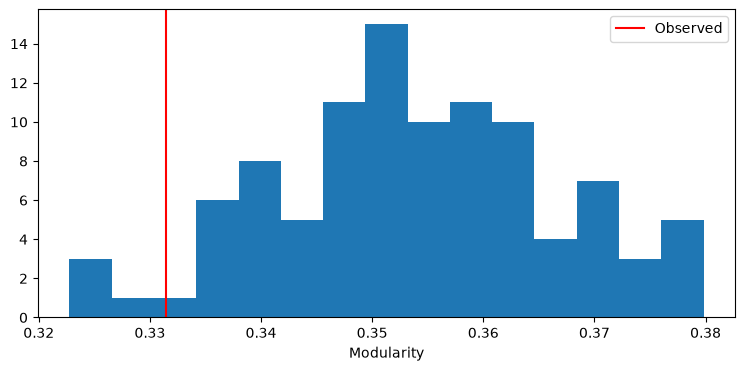

In [8]:
rng=np.random.default_rng(7202);edge_list=list(g.edges());ww=np.array([g[u][v]['weight'] for u,v in edge_list]);null=[]
for i in range(NULL_REPEATS):
 h=g.copy()
 for (u,v),vweight in zip(edge_list,rng.permutation(ww)):h[u][v]['weight']=vweight
 null.append(max(runs(h,count=NULL_SEEDS)[1]))
 if i%20==0:print('Null',i,flush=True)
obs=max(qs[:NULL_SEEDS]);pv=(1+sum(q>=obs for q in null))/(NULL_REPEATS+1)
pd.DataFrame({'null_Q':null}).to_csv(O/'null.csv',index=False)

print('Observed Q:',obs,'Permutation p:',pv)
plt.figure(figsize=(9,4));plt.hist(null,bins=15);plt.axvline(obs,color='red',label='Observed');plt.xlabel('Modularity');plt.legend();plt.show()

## 6. ตรวจ bridge และ centrality
bridge_trips ต้องเปรียบเทียบ community ของเพื่อนบ้านกับจังหวัดเป้าหมาย มี assertion ตรวจผลรวมสองด้าน คะแนน 45/35/20 เป็นคะแนนคัดกรองสมมติ **ไม่ใช้เป็น objective เลือกฐาน** ระยะ 1/weight สำหรับ betweenness ไม่ใช่ระยะถนน

In [9]:
# Correct bridge calculation uses the neighbour, not the focal node.
cid={v:i for i,c in enumerate(p) for v in c};bridge={v:sum(a['weight'] for u,a in g[v].items() if cid[u]!=cid[v]) for v in g}
assert abs(sum(bridge.values())-2*sum(a['weight'] for u,v,a in g.edges(data=True) if cid[u]!=cid[v]))<1e-6
h=g.copy()
for u,v,a in h.edges(data=True):a['distance']=1/a['weight']
bet=nx.betweenness_centrality(h,weight='distance');rank=pd.DataFrame({'province':nodes,'strength':[g.degree(v,weight='weight') for v in nodes],'betweenness':[bet[v] for v in nodes],'bridge_trips':[bridge[v] for v in nodes]})
rank['score']=sum(coef*(rank[col]-rank[col].min())/(rank[col].max()-rank[col].min()) for col,coef in [('strength',.45),('betweenness',.35),('bridge_trips',.2)])
rank.sort_values('score',ascending=False).to_csv(O/'corrected_rank.csv',index=False,encoding='utf-8-sig')

display(rank.sort_values('score',ascending=False).head(10))

,province,strength,betweenness,bridge_trips,score
8,ชลบุรี,151513.0,0.553333,41600.0,0.950564
30,พระนครศรีอยุธยา,117413.0,0.207719,55259.0,0.680078
18,นครราชสีมา,120415.0,0.226316,46002.0,0.667255
52,สมุทรปราการ,77783.0,0.160000,50971.0,0.516633
4,กำแพงเพชร,67863.0,0.188421,45056.0,0.483730
58,สุพรรณบุรี,87943.0,0.056491,45162.0,0.460321
20,นครสวรรค์,84907.0,0.060351,37239.0,0.425067
45,ลพบุรี,83693.0,0.048772,33210.0,0.399554
54,สมุทรสาคร,39100.0,0.330526,14298.0,0.376838
55,สระบุรี,64545.0,0.000000,30873.0,0.303357


## 7. Model A และ Model B
A เพิ่ม coverage รวมเมื่อกำหนด k=2 หรือ 3; B เพิ่ม floor รายกลุ่มที่ส่วนแบ่งต้นทาง ≥10% ทดลอง 30/50/70%

coverage = เที่ยวจากจังหวัดต้นทางที่มีฐานในรัศมี / เที่ยวทั้งหมดในพอร์ต นับไม่ซ้ำ ไม่ใช่รายได้หรือส่วนแบ่งตลาดจริง สถานะ infeasible คือไม่มีชุดฐานผ่านเงื่อนไข ไม่ใช่รันผิด

In [10]:
important=[i for i in range(len(p)) if w[lab==i].sum()/w.sum()>=.1]
def solve(ww,k,floor=None,A=A):
 con=[LinearConstraint(np.c_[-A,np.eye(n)],-np.inf,0),LinearConstraint(np.r_[np.ones(n),np.zeros(n)][None,:],k,k)]
 if floor is not None:
  for i in important:
   z=ww*(lab==i);con.append(LinearConstraint(np.r_[np.zeros(n),z/ z.sum()][None,:],floor,np.inf))
 result=milp(np.r_[np.zeros(n),-ww/ww.sum()],integrality=np.ones(2*n),bounds=Bounds(0,1),constraints=con,options={'mip_rel_gap':0,'time_limit':45})
 if result.status==2:return None,None
 assert result.success,result.message
 ix=np.flatnonzero(result.x[:n]>.5);return ix,A[:,ix].any(1)
models=[];groups=[];frozen={}
for k in [2,3]:
 for floor in [None,.3,.5,.7]:
  name=f'A_{k}' if floor is None else f'B_{k}_{floor}'
  ix,cv=solve(w,k,floor)
  if ix is None:models.append(dict(model=name,status='infeasible'));continue
  frozen[name]=(ix,cv,k);models.append(dict(model=name,status='optimal',sites=' / '.join(nodes[i] for i in ix),coverage=100*w[cv].sum()/w.sum()))
  for i,c in enumerate(p):
   mask=lab==i;groups.append(dict(model=name,community=i,important=i in important,members=' / '.join(sorted(c)),market_share=100*w[mask].sum()/w.sum(),coverage=100*w[mask&cv].sum()/w[mask].sum() if w[mask].sum() else None))
print('MILP done',flush=True)

models_df=pd.DataFrame(models);display(models_df)
for name,(ix,cv,k) in frozen.items():
    assert len(ix)==k
    assert np.array_equal(cv,(D.values[:,ix]<=RADIUS_KM).any(axis=1))

MILP done


,model,status,sites,coverage
0,A_2,optimal,พิษณุโลก / สระบุรี,66.424654
1,B_2_0.3,optimal,พิษณุโลก / สระบุรี,66.424654
2,B_2_0.5,infeasible,NaN,NaN
3,B_2_0.7,infeasible,NaN,NaN
4,A_3,optimal,พิษณุโลก / มหาสารคาม / สระบุรี,82.286496
5,B_3_0.3,optimal,พิษณุโลก / มหาสารคาม / สระบุรี,82.286496
6,B_3_0.5,optimal,พิจิตร / มหาสารคาม / สมุทรสาคร,80.111310
7,B_3_0.7,infeasible,NaN,NaN


## 8. ตรวจย้อนหลังด้วยฐานที่ตรึงไว้
เลือก A ใหม่ภายใต้ k เดิมเป็น benchmark ของทุกโมเดล ไม่ใช่ regret เทียบ B ที่มี constraints เหมือนกัน ใช้เดือนร่วมและ dedup sensitivity แยกกัน บางช่วงทับซ้อน จึงไม่ใช่ independent tests หรือ unseen holdout

เลข community แต่ละช่วงเทียบตรง ๆ ไม่ได้ ใช้ ARI เทียบสมาชิก

In [11]:
temporal=[];community_time=[];common=sorted(set(d.month)&set(old.month))
cases={'2025_matched':old[old.month.isin(common)],'2026_matched':d[d.month.isin(common)],'2025_matched_dedup':old[old.month.isin(common)].drop_duplicates(subset=[c for c in old.columns if c!='id'])}
cases.update({m:d[d.month==m] for m in sorted(d.month.unique())})
for name,df in cases.items():
 gg=graph(df);pp,qq=runs(gg,count=20);ll=labels(pp[int(np.argmax(qq))]);ww=weights(df)
 community_time.append(dict(period=name,ARI_to_2026=ari(lab,ll),groups=len(set(ll))))
 for model,(ix,cv,k) in frozen.items():
  _,best=solve(ww,k);temporal.append(dict(period=name,model=model,fixed_coverage=100*ww[cv].sum()/ww.sum(),unconstrained_reoptimized=100*ww[best].sum()/ww.sum(),loss_pp=100*(ww[best].sum()-ww[cv].sum())/ww.sum()))
  for i in set(ll):
   mask=ll==i;community_time.append(dict(period=name,model=model,community=i,origin_share=ww[mask].sum()/ww.sum(),coverage=ww[mask&cv].sum()/ww[mask].sum() if ww[mask].sum() else None))
frames={'resolution':validation,'models':models,'community_coverage':groups,'temporal':temporal,'temporal_communities':community_time}
for name,rr in frames.items():pd.DataFrame(rr).to_csv(O/(name+'.csv'),index=False,encoding='utf-8-sig')
quality=pd.crosstab(d['product'],d.month);quality.to_csv(O/'product_month_rows.csv',encoding='utf-8-sig')

display(pd.DataFrame(temporal).groupby('model').agg(min_coverage=('fixed_coverage','min'),max_coverage=('fixed_coverage','max'),max_loss_pp=('loss_pp','max')))
(O/'summary.json').write_text(json.dumps({'observed_Q':float(obs),'null_p':float(pv),'models':models},ensure_ascii=False,indent=2),encoding='utf8');

,min_coverage,max_coverage,max_loss_pp
model,,,
A_2,64.002687,68.443635,2.227261
A_3,79.935752,83.572290,0.192291
B_2_0.3,64.002687,68.443635,2.227261
B_3_0.3,79.935752,83.572290,0.192291
B_3_0.5,76.856051,83.764580,3.860186


## 9. กราฟผลจริงและ Network ที่อ่านง่าย
กราฟ Network แสดงจังหวัดทั้งหมด สีคือกลุ่มที่รันได้จริง ขนาดจุดคือ strength ดาวคือฐาน A สามฐาน จัดกลุ่มแยกเพื่ออ่าน ไม่ใช่แผนที่หรือหลักฐานว่ากลุ่มแยกขาด

ชื่อไทยต้องมีฟอนต์ไทยในเครื่อง เซลล์เลือก Tahoma/Noto Sans Thai/Th Sarabun หากไม่มีจะแสดงรหัสจังหวัด พร้อมตารางรหัสประกอบ เพื่อไม่ให้ชื่อเป็นสี่เหลี่ยม

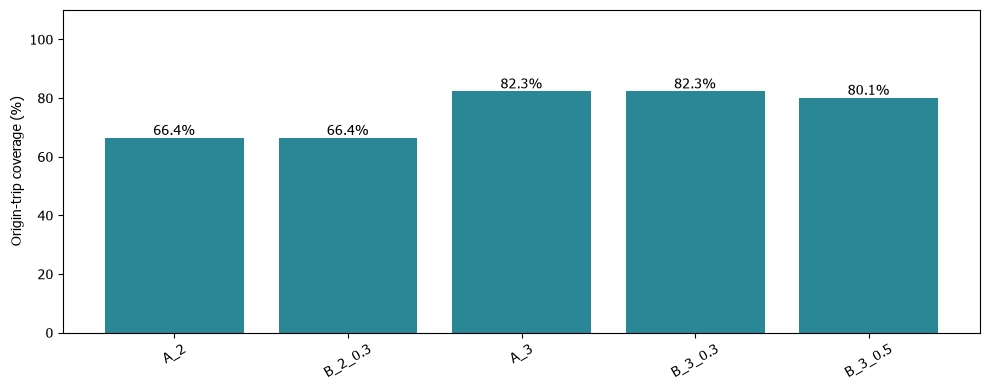

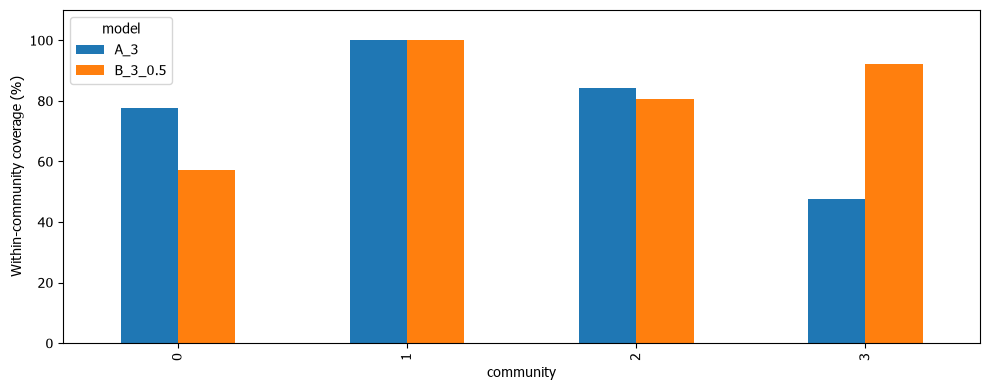

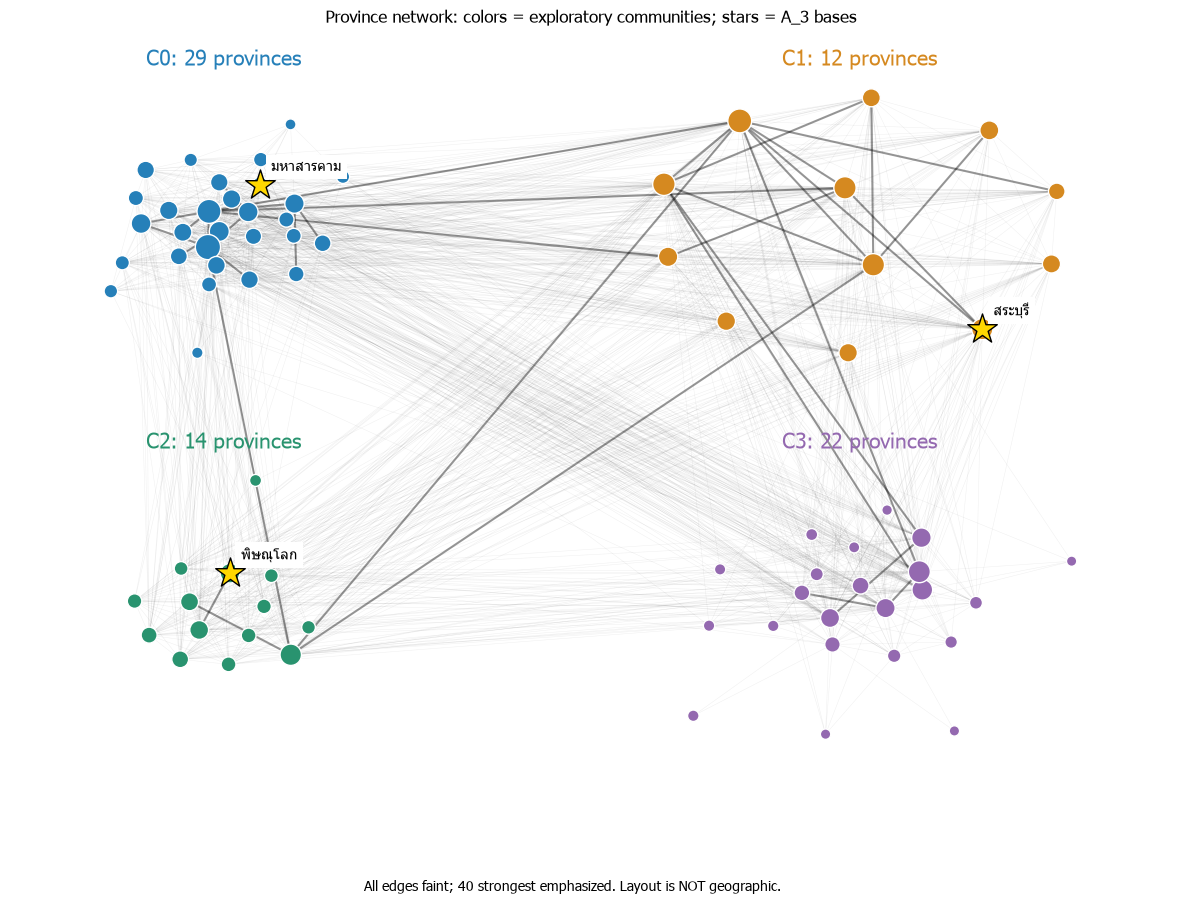

,base,code
0,พิษณุโลก,P36
1,มหาสารคาม,P38
2,สระบุรี,P56


In [12]:
from matplotlib import font_manager
available={f.name for f in font_manager.fontManager.ttflist}
thai_font=next((f for f in ['Tahoma','Noto Sans Thai','TH Sarabun New'] if f in available),None)
if thai_font: plt.rcParams['font.family']=thai_font
node_codes={v:f'P{i+1:02d}' for i,v in enumerate(nodes)}
pd.DataFrame({'code':list(node_codes.values()),'province':nodes}).to_csv(O/'province_codes.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,4))
valid=models_df[models_df.status=='optimal']; bars=ax.bar(valid.model,valid.coverage,color='#298796');ax.bar_label(bars,fmt='%.1f%%');ax.set_ylim(0,110);ax.set_ylabel('Origin-trip coverage (%)');plt.xticks(rotation=30);plt.tight_layout();plt.savefig(O/'coverage.png',dpi=160);plt.show()

groups_df=pd.DataFrame(groups)
comparison=groups_df[groups_df.model.isin(['A_3','B_3_0.5'])].pivot(index='community',columns='model',values='coverage')
comparison.plot.bar(figsize=(10,4),ylim=(0,110),ylabel='Within-community coverage (%)');plt.tight_layout();plt.savefig(O/'community_coverage.png',dpi=160);plt.show()

from matplotlib.colors import ListedColormap
palette=ListedColormap(['#2680B9','#D58920','#29936F','#9469B0']);positions={}; m=len(p)
for i,group in enumerate(p):
    center=np.array([3*(i%2),-3*(i//2)])
    sub=g.subgraph(sorted(group)).copy()
    local=nx.spring_layout(sub,seed=7202,weight=None,iterations=300)
    for v,xy in local.items():positions[v]=center+xy
strength=dict(g.degree(weight='weight'));mx=max(strength.values());base_names={nodes[i] for i in frozen['A_3'][0]}
top=sorted(g.edges(),key=lambda e:g[e[0]][e[1]]['weight'],reverse=True)[:40]
fig,ax=plt.subplots(figsize=(15,10))
nx.draw_networkx_edges(g,positions,ax=ax,alpha=.06,width=.4)
nx.draw_networkx_edges(g,positions,edgelist=top,ax=ax,alpha=.4,width=1.5)
nx.draw_networkx_nodes(g,positions,ax=ax,node_color=[palette(cid[v]%4) for v in g],node_size=[50+280*np.sqrt(strength[v]/mx) for v in g],edgecolors='white')
for v in base_names:
    ax.scatter(*positions[v],s=500,marker='*',c='gold',edgecolors='black',zorder=5)
    ax.annotate(v if thai_font else node_codes[v],positions[v],xytext=(8,10),textcoords='offset points',bbox=dict(fc='white',ec='none'),zorder=6)
ax.set_title('Province network: colors = exploratory communities; stars = A_3 bases')
for i,group in enumerate(p):
    ax.text(3*(i%2),-3*(i//2)+1.25,f'C{i}: {len(group)} provinces',ha='center',color=palette(i%4),fontsize=15)
ax.axis('off');fig.text(.5,.02,'All edges faint; 40 strongest emphasized. Layout is NOT geographic.',ha='center');plt.savefig(O/'network.png',dpi=170,bbox_inches='tight');plt.show()
display(pd.DataFrame({'base':sorted(base_names),'code':[node_codes[v] for v in sorted(base_names)]}))

## 9.1 เครือข่ายบนพิกัดจังหวัด: กลุ่มตลาดและฐาน Model A
เพิ่มสองภาพจากข้อมูลและผลเดิม:
1. **Market groups** ไม่มีดาว เพื่ออ่านกลุ่มเชิงสำรวจบนพิกัดจังหวัด
2. **Model A bases** ดาวเป็นฐาน A สามฐาน จุดจางคือต้นทางที่ไม่อยู่ในรัศมีบริการตาม distance matrix

ขนาดจุดในสองภาพนี้ = เที่ยวต้นทาง (ต่างจากกราฟ Network ก่อนหน้าที่ใช้ strength)
สี = community เชิงสำรวจ ยังไม่ใช่เขตตลาดที่ยืนยันแล้ว แสดงเฉพาะ 60 เส้นที่มีเที่ยวรวมสองทิศทางมากที่สุด

วงรัศมีที่วาดเป็น **ellipse approximation** ของระยะ 150 กม. บนพิกัดละติจูด/ลองจิจูด คำนวณ coverage จาก Haversine ใน distance matrix เดิม ไม่ได้ใช้ ellipse ตัดสินว่าครอบคลุมหรือไม่ ภาพเป็นเครือข่ายบนพิกัด ไม่ได้มีเส้นเขตประเทศไทย และไม่ได้แสดงระยะถนนจริง

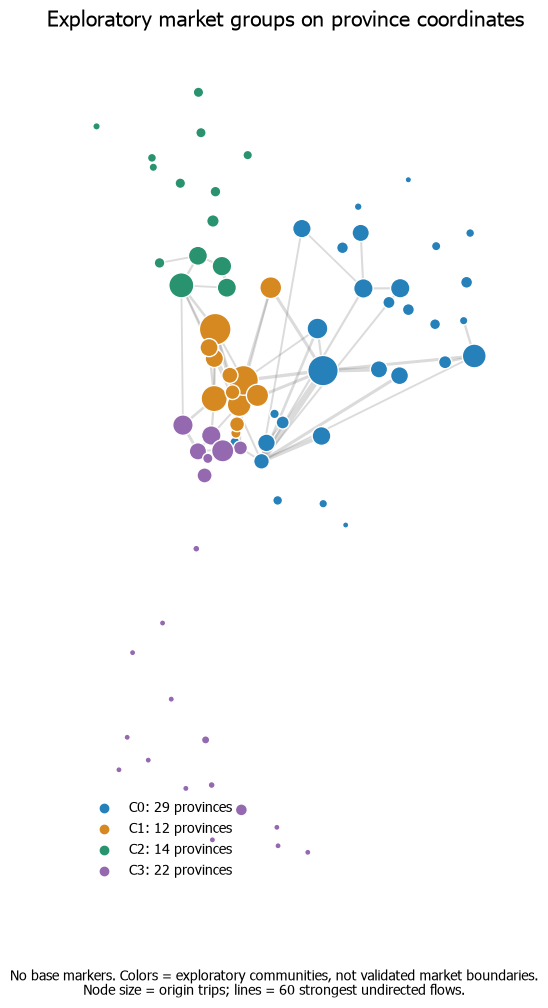

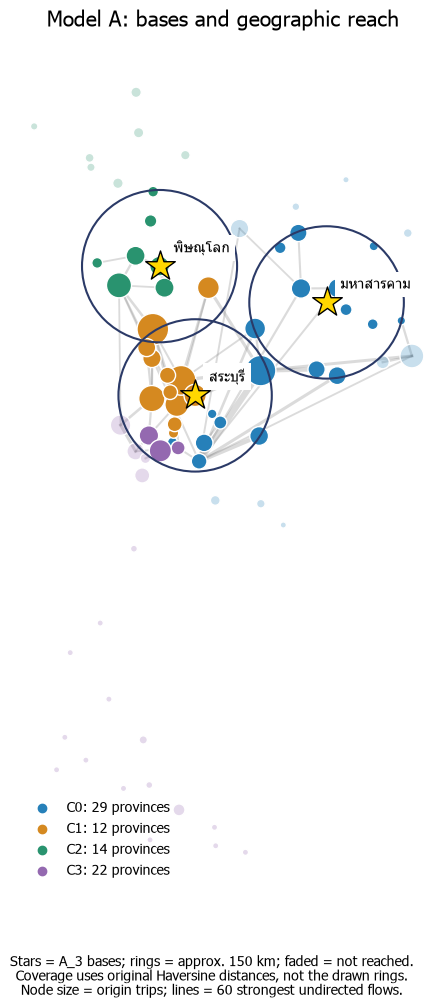

In [13]:
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap
palette = ListedColormap(['#2680B9','#D58920','#29936F','#9469B0']) if len(p)<=4 else plt.get_cmap('tab20',len(p))
# Reindex explicitly: coordinates must match the node order used by the MILP.
map_coords=coords.loc[nodes]
x=map_coords.LNG.to_numpy(); y=map_coords.LAT.to_numpy()
index_by_node={v:i for i,v in enumerate(nodes)}
top=sorted(g.edges(),key=lambda e:g[e[0]][e[1]]['weight'],reverse=True)[:60]
wmax=max((g[u][v]['weight'] for u,v in top),default=1)
ix_A3,cv_A3,_=frozen['A_3']
assert abs(100*w[cv_A3].sum()/w.sum()-models_df.set_index('model').loc['A_3','coverage'])<1e-9

def thai_map(path,bases):
    fig,ax=plt.subplots(figsize=(9,11))
    for u,v in top:
        i,j=index_by_node[u],index_by_node[v]
        ax.plot([x[i],x[j]],[y[i],y[j]],color='grey',alpha=.28,
                lw=.5+4*g[u][v]['weight']/wmax,zorder=1)
    colors=np.array([palette(cid[v]) for v in nodes])
    colors[:,3]=[1 if (not bases or cv_A3[i]) else .25 for i in range(n)]
    ax.scatter(x,y,s=20+500*w/w.max(),c=colors,edgecolors='white',zorder=2)
    if bases:
        r=RADIUS_KM/111
        for i in ix_A3:
            ax.add_patch(Ellipse((x[i],y[i]),2*r/np.cos(np.radians(y[i])),2*r,
                               fill=False,ec='#2B3A67',lw=1.5,zorder=3))
            ax.scatter(x[i],y[i],s=500,marker='*',c='gold',edgecolors='black',zorder=5)
            ax.annotate(nodes[i] if thai_font else node_codes[nodes[i]],(x[i],y[i]),
                        xytext=(10,10),textcoords='offset points',
                        bbox=dict(fc='white',ec='none'),zorder=6)
    for i in range(len(p)):
        ax.scatter([],[],color=palette(i),label=f'C{i}: {len(p[i])} provinces')
    ax.legend(frameon=False,loc='lower left')
    ax.set_aspect(1/np.cos(np.radians(13)));ax.axis('off')
    ax.set_title('Model A: bases and geographic reach' if bases else 'Exploratory market groups on province coordinates',fontsize=15,pad=20)
    caption=f'Stars = A_3 bases; rings = approx. {RADIUS_KM} km; faded = not reached.\nCoverage uses original Haversine distances, not the drawn rings.' if bases else 'No base markers. Colors = exploratory communities, not validated market boundaries.'
    fig.text(.5,.025,caption+'\nNode size = origin trips; lines = 60 strongest undirected flows.',ha='center',fontsize=10)
    fig.subplots_adjust(bottom=.12)
    plt.savefig(path,dpi=160,bbox_inches='tight');plt.show()

thai_map(O/'map_groups.png',bases=False)
thai_map(O/'map_bases.png',bases=True)


## 11. ตรวจเพิ่มตามมาตรฐานรายวิชา (course-alignment checks)
เพิ่มหลังทบทวนเทียบ rubric และเนื้อหาบทที่ 1–12 **ผลในส่วน 1–9 ไม่ถูกแก้** ส่วนนี้ตรวจซ้ำด้วยวิธีที่รายวิชาสอน และเติมช่องว่างที่ rubric ระบุ

| ส่วน | บท | คำถาม |
|---|---|---|
| 11.1 | Ch 4, 6 | หกการตัดสินใจในการสร้างกราฟ, data-collection spec, validation sample |
| 11.2 | Ch 8 | รูปทรงเครือข่ายเทียบกราฟสุ่มขนาดเดียวกัน |
| 11.3 | Ch 9 | Check 2 แบบ rewired copies, Check 3 ความมั่นใจรายจังหวัด, algorithm ที่สอง |
| 11.4 | Ch 7 | centrality แบบมีทิศทาง: เลือก metric จากคำถามธุรกิจ |
| 11.5 | Ch 10 | เลือกฐาน = เลือก seed: random / ranking / greedy / optimal |
| 11.6 | — | ความไวต่อรัศมี น้ำหนัก ชุดฐานใกล้เคียง และระยะถนนจริงจากข้อมูล |
| 11.7 | Ch 1, 3 | ใช้ edge ในการตัดสินใจ: lane (backhaul) coverage |
| 11.8 | — | ตัวเลขในสไลด์ที่เดิมคำนวณนอก Notebook |

### 11.1 หกการตัดสินใจในการสร้างกราฟ (Ch 6) และ data-collection spec (Ch 4)
| การตัดสินใจ | สิ่งที่เลือก | เหตุผล / หลักฐาน |
|---|---|---|
| Schema | node = จังหวัด (77), edge = เที่ยวขนส่งระหว่างจังหวัด; community ใช้ผลรวมสองทิศทาง แต่ coverage และ centrality เก็บทิศทาง (11.4) | หน่วยตัดสินใจคือจังหวัดที่ตั้งฐาน |
| Extraction | ข้อมูล GPS รถบรรทุกแบบตาราง (สนข./ขบ.) ไม่มีข้อความ ไม่ใช้ LLM สกัด | ไม่มี extraction error; text→graph ไม่เกี่ยวกับข้อมูลชุดนี้ |
| Resolution | ชื่อจังหวัด strip แล้ว match ตรงกับ 77 จังหวัด (assert ส่วน 2); จุดกรุงเทพฯ = median พิกัดโรงงาน; ไม่ใช้ชื่อตำบล | ไม่มี merge แบบคลุมเครือ ("When unsure, do not merge") |
| Weighting | trips (ความถี่ที่ต้องรับงาน); ทดสอบ tons (`shipping`) และรวมเที่ยวในจังหวัด ใน 11.6 | ฐานไม่เปลี่ยน (ดู 11.6) |
| Pruning | ไม่ตัด edge (เก็บ 1,308 เส้น) | coverage ใช้ยอดรวม node; edge เล็กแทบไม่กระทบ community แบบมีน้ำหนัก |
| Validation | hash, audit ยอดรวม, สินค้า×เดือนครบ, ปี 2568, และ plausibility sample ด้านล่าง | ด้านล่าง |

**Data-collection spec (ethics gate, Ch 4)**

| แหล่ง | field ที่ใช้ | ฐานทางกฎหมาย / สัญญาอนุญาต | ไม่เก็บ |
|---|---|---|---|
| สนข. otp_69_01 (2569, 2568) | product, month, province_origin/destination, trips, shipping, average_distance, average_duration | Open Data Common, ดาวน์โหลดจาก portal ทางการ (ไม่ scrape) | ทะเบียนรถ บริษัท คนขับ; ไม่เผยแพร่ระดับตำบลในผลลัพธ์ |
| กรมส่งเสริมการปกครองท้องถิ่น province_lat_long | LAT, LNG | CC-BY | — |
| สป.อก. bangkok.csv | พิกัดโรงงานเพื่อหา median จุดเดียว | Open Data Common | ชื่อ/เจ้าของโรงงาน |

PDPA: ไม่มีข้อมูลส่วนบุคคล ใช้ยอดรวมระดับจังหวัดเท่านั้น

In [14]:
# 11.1 Validation sample (Ch 6): physical plausibility of every interprovince OD row in scope
vd=d.copy()
for c in ['shipping','average_distance','average_duration','average_speed']:vd[c]=pd.to_numeric(vd[c],errors='coerce')
vd['centroid_km']=[D.at[a,b] for a,b in zip(vd.province_origin,vd.province_destination)]
far=vd.average_distance<.5*vd.centroid_km-60  # road trip far shorter than province-centre distance: border subdistricts or bad rows
star=vd.subdistrict_origin.astype(str).str.contains('*',regex=False)|vd.subdistrict_destination.astype(str).str.contains('*',regex=False)
validation_sample=pd.Series({'rows':len(vd),'missing_distance_or_duration':int(vd[['average_distance','average_duration']].isna().any(axis=1).sum()),
 'speed_over_100kmh':int((vd.average_speed>100).sum()),'road_far_below_centroid_distance':int(far.sum()),
 'trip_share_of_those_rows_pct':100*vd.trips[far].sum()/vd.trips.sum(),'subdistrict_name_with_star':int(star.sum()),
 'tons_per_trip_median':float((vd.shipping/vd.trips).median())})
display(validation_sample.to_frame('value'))
vd.loc[far,['product','month','province_origin','district_origin','province_destination','district_destination','trips','average_distance','centroid_km']].to_csv(O/'validation_flagged_rows.csv',index=False,encoding='utf-8-sig')
assert validation_sample.trip_share_of_those_rows_pct<1, 'implausible rows now matter: inspect before using results'

,value
rows,39157.000000
missing_distance_or_duration,0.000000
speed_over_100kmh,0.000000
road_far_below_centroid_distance,26.000000
trip_share_of_those_rows_pct,0.335545
subdistrict_name_with_star,6.000000
tons_per_trip_median,27.142857


### 11.2 รูปทรงเครือข่าย (Ch 8)
คำนวณ fingerprint บน topology (ไม่ถ่วงน้ำหนัก ตามบทที่ 8) เทียบกับกราฟสุ่ม G(n, m) ที่มีจำนวนจังหวัดและเส้นเท่ากัน 100 ชุด inside share ใช้ split ที่ดีที่สุดของแต่ละกราฟ (Louvain 10 รอบ)

In [15]:
# 11.2 Structure fingerprint (Ch 8) vs random graphs with the same N and links
def fingerprint(G,seeds=10):
    deg=dict(G.degree());N=G.number_of_nodes();big=G.subgraph(max(nx.connected_components(G),key=len))
    parts_=[nx.community.louvain_communities(G,seed=s) for s in range(seeds)]
    best=max(parts_,key=lambda q:nx.community.modularity(G,q));cg={v:i for i,c in enumerate(best) for v in c}
    hub=max(nx.betweenness_centrality(G).items(),key=lambda kv:kv[1])[0]
    return {'pieces':nx.number_connected_components(G),'density':nx.density(G),
            'centralization':sum(max(deg.values())-v for v in deg.values())/((N-1)*(N-2)),
            'clustering':nx.average_clustering(G),'avg_path':nx.average_shortest_path_length(big),'diameter':nx.diameter(big),
            'inside_share':sum(cg[u]==cg[v] for u,v in G.edges())/G.number_of_edges(),
            'pieces_without_connector':nx.number_connected_components(G.subgraph(set(G)-{hub}))}
topo=nx.Graph(g.edges())
fp=pd.DataFrame({'freight network':fingerprint(topo),
                 'random G(n,m), mean of 100':pd.DataFrame([fingerprint(nx.gnm_random_graph(n,topo.number_of_edges(),seed=s)) for s in range(100)]).mean()})
fp.loc['inside_share_weighted_reported_split','freight network']=sum(a['weight'] for u,v,a in g.edges(data=True) if cid[u]==cid[v])/g.size(weight='weight')
fp.to_csv(O/'structure_fingerprint.csv',encoding='utf-8-sig');display(fp.round(3))
max_partner=max(dict(topo.degree()).items(),key=lambda kv:kv[1]);print('Most trading partners:',max_partner)
assert fp.at['pieces','freight network']==1 and abs(fp.at['density','freight network']-topo.number_of_edges()/(n*(n-1)/2))<1e-12

,freight network,"random G(n,m), mean of 100"
pieces,1.000,1.000
density,0.447,0.447
centralization,0.433,0.141
clustering,0.776,0.447
avg_path,1.574,1.553
diameter,3.000,2.000
inside_share,0.505,0.332
pieces_without_connector,1.000,1.000
inside_share_weighted_reported_split,0.632,NaN


Most trading partners: ('สระบุรี', 66)


### 11.3 สี่การตรวจ community ตามบทที่ 9
**Check 2 (baseline)** บทที่ 9 สร้าง *rewired copies* ที่ทุก node คง degree แล้วนับ copy ที่ Q ≥ ของจริง (กฎ: ≤ 4 จาก 100 = กลุ่มจริง) ส่วน 5 เดิมสลับน้ำหนักบน topology เดิม ซึ่งเป็นคำถามอื่น จึงรายงานครบสามแบบ ไม่เลือกเฉพาะแบบที่ผ่าน:
1. **Topology-only (วิธีเดียวกับ lab บทที่ 9):** `nx.double_edge_swap` บนกราฟไม่ถ่วงน้ำหนัก 10×m ครั้ง ทุกจังหวัดคง degree
2. **Strength-preserving (ฉบับถ่วงน้ำหนัก):** มองเที่ยวเป็น multigraph (บทที่ 3) แล้วสลับปลายเที่ยวแบบสุ่ม ทุกจังหวัดคงจำนวนเที่ยวรวม ไม่มี self-loop
3. **Weight permutation (ส่วน 5 เดิม):** topology เดิม สลับน้ำหนัก

ทุกแบบใช้ best of 10 Louvain เท่ากับของจริง

In [16]:
# 11.3a Check 2 (Ch 9): rewired copies that keep every province's degree / strength
rng_c=np.random.default_rng(72022)
strength_int=np.rint([g.degree(v,weight='weight') for v in nodes]).astype(int)
assert np.allclose(strength_int,[g.degree(v,weight='weight') for v in nodes])
trip_ends=np.repeat(np.arange(n),strength_int)
def strength_copy():
    s=rng_c.permutation(trip_ends);M=np.zeros((n,n));np.add.at(M,(s[0::2],s[1::2]),1);M=M+M.T;np.fill_diagonal(M,0)
    H=nx.Graph();H.add_nodes_from(range(n));H.add_weighted_edges_from((i,j,M[i,j]) for i,j in zip(*np.triu_indices(n,1)) if M[i,j]>0);return H
obs_topo=max(runs(topo,count=NULL_SEEDS)[1])
null_course=[]
for i in range(NULL_REPEATS):
    H=topo.copy();nx.double_edge_swap(H,nswap=10*H.number_of_edges(),max_tries=10**7,seed=int(rng_c.integers(2**31)))
    null_course.append({'strength_preserving_Q':max(runs(strength_copy(),count=NULL_SEEDS)[1]),'topology_only_Q':max(runs(H,count=NULL_SEEDS)[1])})
null_course=pd.DataFrame(null_course);null_course.to_csv(O/'null_course.csv',index=False)
check2=pd.DataFrame([
 dict(baseline='degree-preserving double_edge_swap, unweighted (Ch 9 lab method)',observed_Q=obs_topo,copies_at_or_above=int((null_course.topology_only_Q>=obs_topo).sum()),null_mean=null_course.topology_only_Q.mean(),null_max=null_course.topology_only_Q.max()),
 dict(baseline='strength-preserving rewiring of trip ends (weighted analogue)',observed_Q=obs,copies_at_or_above=int((null_course.strength_preserving_Q>=obs).sum()),null_mean=null_course.strength_preserving_Q.mean(),null_max=null_course.strength_preserving_Q.max()),
 dict(baseline='weight permutation on fixed topology (section 5)',observed_Q=obs,copies_at_or_above=int(sum(q>=obs for q in null)),null_mean=np.mean(null),null_max=max(null))])
check2['p']=(1+check2.copies_at_or_above)/(NULL_REPEATS+1);check2['verdict']=np.where(check2.copies_at_or_above<=4,'real groups (<=4 of 100)','luck cannot be ruled out')
check2.to_csv(O/'check2_baselines.csv',index=False,encoding='utf-8-sig');display(check2.round(4))

,baseline,observed_Q,copies_at_or_above,null_mean,null_max,p,verdict
0,"degree-preserving double_edge_swap, unweighted...",0.1605,0,0.0700,0.0790,0.0099,real groups (<=4 of 100)
1,strength-preserving rewiring of trip ends (wei...,0.3314,0,0.0000,0.0001,0.0099,real groups (<=4 of 100)
2,weight permutation on fixed topology (section 5),0.3314,96,0.3538,0.3798,0.9604,luck cannot be ruled out


In [17]:
# 11.3b Check 3 (Ch 9): confidence = share of the 100 runs a province lands with its usual group-mates; flag < 0.80
conf_df=pd.DataFrame({'province':nodes,'community':lab,'confidence':[co[i,(lab==lab[i])&(np.arange(n)!=i)].mean() for i in range(n)]})
conf_df['stable']=conf_df.confidence>=.8
conf_df.sort_values('confidence').to_csv(O/'community_confidence.csv',index=False,encoding='utf-8-sig')
display(conf_df.groupby('community').agg(provinces=('province','size'),flagged=('stable',lambda s:int((~s).sum())),min_conf=('confidence','min')))
display(conf_df[~conf_df.stable].sort_values('confidence'))
print('A_3 hubs confidence:',conf_df.set_index('province').loc[[nodes[i] for i in frozen['A_3'][0]],'confidence'].round(2).to_dict())

,provinces,flagged,min_conf
community,,,
0,29,0,0.876786
1,12,12,0.377273
2,14,0,1.000000
3,22,0,1.000000


,province,community,confidence,stable
58,สุพรรณบุรี,1,0.377273,False
67,อุทัยธานี,1,0.377273,False
9,ชัยนาท,1,0.495455,False
20,นครสวรรค์,1,0.495455,False
57,สิงห์บุรี,1,0.495455,False
69,อ่างทอง,1,0.495455,False
73,เพชรบูรณ์,1,0.554545,False
21,นนทบุรี,1,0.603636,False
26,ปทุมธานี,1,0.607273,False
30,พระนครศรีอยุธยา,1,0.607273,False


A_3 hubs confidence: {'พิษณุโลก': 1.0, 'มหาสารคาม': 0.98, 'สระบุรี': 0.61}


In [18]:
# 11.3c Second algorithm as cross-check (Ch 9 slide 20): Leiden (modularity) and label propagation vs the Louvain split
def best_of(fn,count=SEEDS):
    pp=[list(fn(s)) for s in range(count)];qq=[nx.community.modularity(g,x,weight='weight') for x in pp];return pp[int(np.argmax(qq))],max(qq)
alt={'Louvain (reported)':(p,nx.community.modularity(g,p,weight='weight')),
     'Leiden (modularity)':best_of(lambda s:nx.community.leiden_communities(g,weight='weight',metric='modularity',seed=s)),
     'Label propagation':best_of(lambda s:nx.community.asyn_lpa_communities(g,weight='weight',seed=s)),
     'Greedy modularity':(nx.community.greedy_modularity_communities(g,weight='weight'),None)}
cross=pd.DataFrame([dict(algorithm=k_,groups=len(v[0]),Q=nx.community.modularity(g,v[0],weight='weight'),ARI_to_reported=ari(lab,labels(v[0]))) for k_,v in alt.items()])
cross.to_csv(O/'community_cross_check.csv',index=False);display(cross.round(3))

,algorithm,groups,Q,ARI_to_reported
0,Louvain (reported),4,0.331,1.000
1,Leiden (modularity),4,0.331,1.000
2,Label propagation,2,0.284,0.458
3,Greedy modularity,4,0.328,0.901


### 11.4 Centrality แบบมีทิศทาง (Ch 7): เลือก metric จากคำถาม
ฐานรับงาน *ต้นทาง* ดังนั้น metric ที่ตรงคำถามคือ **out-strength** (เที่ยวออก) ซึ่งเป็นน้ำหนักเดียวกับที่ Model A ใช้ ส่วน strength (เข้า+ออก) ปนปลายทางเข้ามา บทที่ 7: "Say what you ignored" และ "PageRank needs the arrows"

| Metric | คำถามธุรกิจ | ใช้ในการตัดสินใจ |
|---|---|---|
| Out-strength | จังหวัดไหนมีงานให้รับมากที่สุด | ใช่ (น้ำหนัก Model A) |
| In-strength | รถจะไปจบที่ไหน ต้องหางานขากลับที่ไหน | ใช่ (lane coverage 11.7, Neo4j) |
| Partners (degree) | จังหวัดไหนค้าขายกับคู่ค้าหลายจังหวัด | บรรยาย |
| PageRank (มีทิศ) | ปลายทางที่รับสินค้าจากต้นทางสำคัญ (ท่าเรือ โรงงาน) | บรรยาย |
| Betweenness (1/trips) | ตำแหน่ง broker ในแบบแผนการค้า **ไม่ใช่เส้นทางรถ** เพราะ edge ใน OD เป็นเที่ยวตรงอยู่แล้ว | ไม่ใช้ |
| Closeness | ไม่ช่วยแยก: diameter = 3 ทุกจังหวัดถึงกันใน 1–3 ขั้น | ไม่ใช้ |

In [19]:
# 11.4 Directed centrality (Ch 7)
dg=nx.DiGraph();dg.add_nodes_from(nodes)
for (a,b),t in d.groupby(['province_origin','province_destination']).trips.sum().items():dg.add_edge(a,b,weight=float(t))
pr=nx.pagerank(dg,weight='weight')
cent_df=pd.DataFrame({'province':nodes,'out_trips':[dg.out_degree(v,weight='weight') for v in nodes],'in_trips':[dg.in_degree(v,weight='weight') for v in nodes],
                      'partners':[g.degree(v) for v in nodes],'pagerank':[pr[v] for v in nodes]}).merge(rank[['province','strength','betweenness','bridge_trips','score']],on='province')
cent_df['out_in_ratio']=cent_df.out_trips/cent_df.in_trips.replace(0,np.nan)
assert np.allclose(cent_df.out_trips,w) and np.allclose(cent_df.out_trips+cent_df.in_trips,cent_df.strength)
cent_df.sort_values('out_trips',ascending=False).to_csv(O/'centrality_directed.csv',index=False,encoding='utf-8-sig')
display(pd.DataFrame({m:cent_df.nlargest(3,m).province.tolist() for m in ['out_trips','in_trips','strength','partners','pagerank','betweenness']}).T.rename(columns=lambda c:f'#{c+1}'))
display(cent_df.nlargest(8,'strength')[['province','out_trips','in_trips','out_in_ratio']].round(2))

,#1,#2,#3
out_trips,นครสวรรค์,นครราชสีมา,ลพบุรี
in_trips,ชลบุรี,พระนครศรีอยุธยา,สมุทรปราการ
strength,ชลบุรี,นครราชสีมา,พระนครศรีอยุธยา
partners,สระบุรี,สมุทรปราการ,นครปฐม
pagerank,ชลบุรี,สมุทรปราการ,พระนครศรีอยุธยา
betweenness,ชลบุรี,สมุทรสาคร,นครราชสีมา


,province,out_trips,in_trips,out_in_ratio
8,ชลบุรี,13802.0,137711.0,0.10
18,นครราชสีมา,59198.0,61217.0,0.97
30,พระนครศรีอยุธยา,35278.0,82135.0,0.43
58,สุพรรณบุรี,43168.0,44775.0,0.96
20,นครสวรรค์,64337.0,20570.0,3.13
45,ลพบุรี,56270.0,27423.0,2.05
52,สมุทรปราการ,10552.0,67231.0,0.16
4,กำแพงเพชร,39366.0,28497.0,1.38


### 11.5 เลือกฐาน = เลือก seed (Ch 10, Idea 5)
ฐานแต่ละแห่ง "เข้าถึง" ต้นทางในรัศมีแบบขั้นเดียว (p = 1) จึงเป็นโจทย์เลือก seed ภายใต้งบเท่ากัน เทียบแบบบทที่ 10: random, ranking ตาม metric ต่าง ๆ, greedy (เพิ่มทีละฐานที่เพิ่ม coverage มากที่สุด, รับประกัน ≥ 63% ของค่าดีที่สุด) และ optimal (MILP) ใช้กฎ 150 กม. และ coverage เดียวกันทุกวิธี random คำนวณจากทุกชุดที่เป็นไปได้ (exact)

,k,method,hubs,coverage,sum_of_singles
0,2,Random (mean of all sets),,29.5,NaN
1,2,Random (95th percentile),,56.0,NaN
2,2,Top by strength (in+out),ชลบุรี / นครราชสีมา,39.4,45.8
3,2,Top by out-strength (origin trips),นครสวรรค์ / นครราชสีมา,55.6,55.6
4,2,Top by in-strength,ชลบุรี / พระนครศรีอยุธยา,45.1,68.2
5,2,Top by partners (degree),สระบุรี / สมุทรปราการ,50.9,83.3
6,2,Top by betweenness,ชลบุรี / สมุทรสาคร,41.2,65.9
7,2,Top by bridge trips,พระนครศรีอยุธยา / สมุทรปราการ,42.8,80.0
8,2,Top by screening score,ชลบุรี / พระนครศรีอยุธยา,45.1,68.2
9,2,Top by PageRank,ชลบุรี / สมุทรปราการ,41.2,65.9


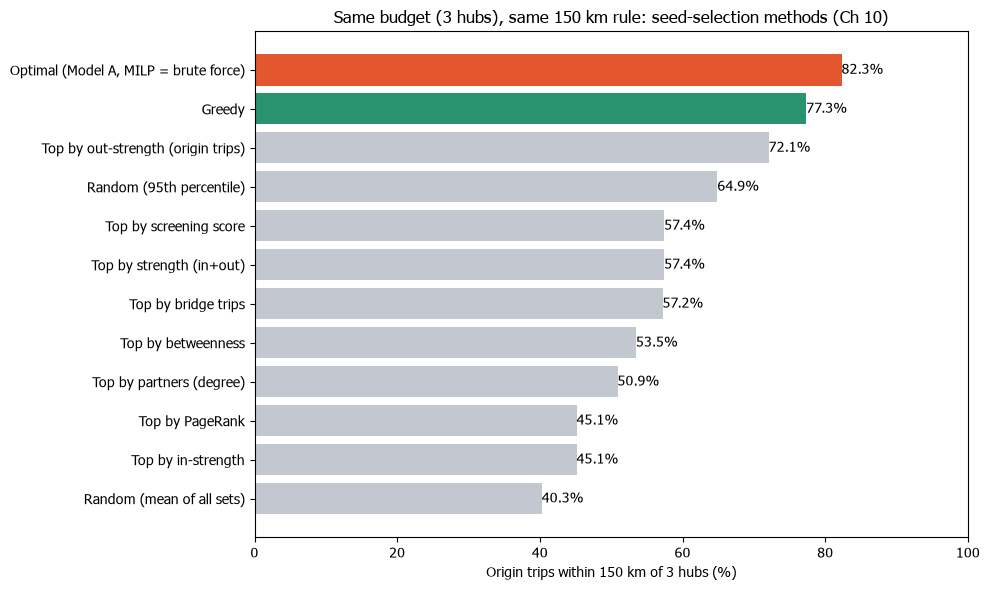

In [20]:
# 11.5 Seed-selection comparison (Ch 10) at the same budget and the same scoring
from itertools import combinations
def coverage_of(ix_,Acov=A,wv=w):return 100*wv[Acov[:,list(ix_)].any(1)].sum()/wv.sum()
def all_sets(kk,Acov=A,wv=w):
    S=np.array(list(combinations(range(n),kk)));return S,100*(wv@Acov[:,S].any(2))/wv.sum()
def greedy(kk,Acov=A,wv=w):
    S=[]
    for _ in range(kk):S.append(max((j for j in range(n) if j not in S),key=lambda j:coverage_of(S+[j],Acov,wv)))
    return S
seed_rows=[]
for kk in [2,3]:
    S,c=all_sets(kk);opt_ix=frozen[f'A_{kk}'][0]
    assert abs(c.max()-coverage_of(opt_ix))<1e-9, 'MILP optimum must equal brute force'
    seed_rows+=[dict(k=kk,method='Random (mean of all sets)',hubs='',coverage=c.mean()),dict(k=kk,method='Random (95th percentile)',hubs='',coverage=np.percentile(c,95))]
    for label,col in [('Top by strength (in+out)','strength'),('Top by out-strength (origin trips)','out_trips'),('Top by in-strength','in_trips'),('Top by partners (degree)','partners'),
                      ('Top by betweenness','betweenness'),('Top by bridge trips','bridge_trips'),('Top by screening score','score'),('Top by PageRank','pagerank')]:
        top_ix=[nodes.index(v) for v in cent_df.nlargest(kk,col).province]
        seed_rows.append(dict(k=kk,method=label,hubs=' / '.join(nodes[i] for i in top_ix),coverage=coverage_of(top_ix),sum_of_singles=sum(coverage_of([i]) for i in top_ix)))
    gr=greedy(kk);seed_rows.append(dict(k=kk,method='Greedy',hubs=' / '.join(nodes[i] for i in gr),coverage=coverage_of(gr)))
    seed_rows.append(dict(k=kk,method='Optimal (Model A, MILP = brute force)',hubs=' / '.join(nodes[i] for i in opt_ix),coverage=coverage_of(opt_ix)))
seed_df=pd.DataFrame(seed_rows);seed_df.to_csv(O/'seeding.csv',index=False,encoding='utf-8-sig');display(seed_df.round(1))
s3=seed_df[seed_df.k==3].sort_values('coverage')
fig,ax=plt.subplots(figsize=(10,6));bars=ax.barh(s3.method,s3.coverage,color=['#E4572E' if m.startswith('Optimal') else '#29936F' if m=='Greedy' else '#C3C7D0' for m in s3.method])
ax.bar_label(bars,fmt='%.1f%%');ax.set_xlim(0,100);ax.set_xlabel('Origin trips within 150 km of 3 hubs (%)');ax.set_title('Same budget (3 hubs), same 150 km rule: seed-selection methods (Ch 10)')
plt.tight_layout();plt.savefig(O/'seeding.png',dpi=160);plt.show()

### 11.6 ความไว: รัศมี น้ำหนัก ชุดฐานใกล้เคียง และระยะถนนจริง
ข้อมูล สนข. มี `average_distance` (ระยะวิ่งจริงจาก GPS) และ `average_duration` ต่อเที่ยว จึงใช้ปรับเทียบรัศมี 150 กม. เส้นตรงได้จากข้อมูลเอง

,radius_km,k,hubs,hub_groups,coverage,A3_sites_coverage
0,100,2,ปทุมธานี / พิจิตร,C1 / C2,54.8,35.7
1,100,3,ปทุมธานี / พิจิตร / ยโสธร,C1 / C2 / C0,63.7,42.2
2,125,2,พระนครศรีอยุธยา / พิจิตร,C1 / C2,61.3,44.9
3,125,3,พระนครศรีอยุธยา / พิจิตร / ยโสธร,C1 / C2 / C0,72.8,51.5
4,150,2,พิษณุโลก / สระบุรี,C2 / C1,66.4,66.4
5,150,3,พิษณุโลก / มหาสารคาม / สระบุรี,C2 / C0 / C1,82.3,82.3
6,175,2,สระบุรี / เพชรบูรณ์,C1 / C1,75.6,73.2
7,175,3,มหาสารคาม / สระบุรี / อุตรดิตถ์,C0 / C1 / C2,92.0,90.7
8,200,2,ชัยนาท / มหาสารคาม,C1 / C0,84.8,77.7
9,200,3,กาฬสินธุ์ / ปทุมธานี / อุตรดิตถ์,C0 / C1 / C2,98.1,96.2


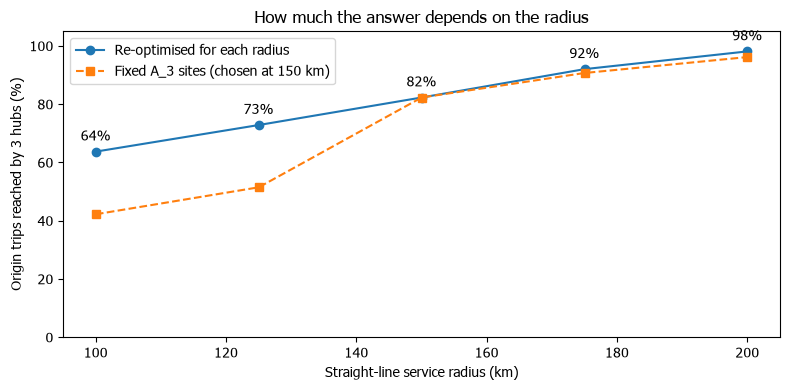

In [21]:
# 11.6a Radius sweep: Model A re-solved at each radius (MILP checked against brute force)
radius_rows=[]
for R in [100,125,150,175,200]:
    AR=(D.values<=R).astype(float)
    for kk in [2,3]:
        ixR,cvR=solve(w,kk,A=AR);_,cb=all_sets(kk,AR);assert abs(cb.max()-100*w[cvR].sum()/w.sum())<1e-9
        radius_rows.append(dict(radius_km=R,k=kk,hubs=' / '.join(nodes[i] for i in ixR),hub_groups=' / '.join(f'C{lab[i]}' for i in ixR),coverage=100*w[cvR].sum()/w.sum(),
                                A3_sites_coverage=coverage_of(frozen[f'A_{kk}'][0],AR)))
radius_df=pd.DataFrame(radius_rows);radius_df.to_csv(O/'sensitivity_radius.csv',index=False,encoding='utf-8-sig');display(radius_df.round(1))
r3=radius_df[radius_df.k==3]
fig,ax=plt.subplots(figsize=(8,4));ax.plot(r3.radius_km,r3.coverage,'o-',label='Re-optimised for each radius');ax.plot(r3.radius_km,r3.A3_sites_coverage,'s--',label='Fixed A_3 sites (chosen at 150 km)')
for _,r in r3.iterrows():ax.annotate(f"{r.coverage:.0f}%",(r.radius_km,r.coverage),textcoords='offset points',xytext=(0,8),ha='center')
ax.set_xlabel('Straight-line service radius (km)');ax.set_ylabel('Origin trips reached by 3 hubs (%)');ax.set_ylim(0,105);ax.legend();ax.set_title('How much the answer depends on the radius')
plt.tight_layout();plt.savefig(O/'sensitivity_radius.png',dpi=160);plt.show()
assert (r3.hub_groups.str.split(' / ').apply(lambda s:sorted(s))==[['C0','C1','C2']]*len(r3)).all(), 'k=3: one hub per North/Central/Northeast group at every radius'

In [22]:
# 11.6b Near-optimal hub sets at 150 km (ties and near-ties matter for site choice)
near=[]
for kk in [2,3]:
    S,c=all_sets(kk);order=np.argsort(-c)[:5]
    near+=[dict(k=kk,rank=r+1,hubs=' / '.join(nodes[i] for i in S[j]),hub_groups=' / '.join(f'C{lab[i]}' for i in S[j]),coverage=c[j],gap_pp=c[order[0]]-c[j]) for r,j in enumerate(order)]
near_df=pd.DataFrame(near);near_df.to_csv(O/'near_optimal.csv',index=False,encoding='utf-8-sig');display(near_df.round(2))

,k,rank,hubs,hub_groups,coverage,gap_pp
0,2,1,พิษณุโลก / สระบุรี,C2 / C1,66.42,0.00
1,2,2,นครนายก / พิจิตร,C0 / C2,65.91,0.52
2,2,3,ปราจีนบุรี / พิจิตร,C0 / C2,65.91,0.52
3,2,4,พิจิตร / สระบุรี,C2 / C1,65.91,0.52
4,2,5,นครสวรรค์ / ปราจีนบุรี,C1 / C0,64.60,1.83
5,3,1,พิษณุโลก / มหาสารคาม / สระบุรี,C2 / C0 / C1,82.29,0.00
6,3,2,พิจิตร / มหาสารคาม / สระบุรี,C2 / C0 / C1,81.77,0.52
7,3,3,ปราจีนบุรี / พิจิตร / มหาสารคาม,C0 / C2 / C0,81.77,0.52
8,3,4,นครนายก / พิจิตร / มหาสารคาม,C0 / C2 / C0,81.77,0.52
9,3,5,นครสวรรค์ / มหาสารคาม / สระบุรี,C1 / C0 / C1,80.46,1.83


In [23]:
# 11.6c Edge-weight choice (Ch 6): trips vs tons vs adding intra-province trips vs origin+destination
scope=raw[raw['product'].isin(P)]
tons=d.assign(shipping=pd.to_numeric(d.shipping)).groupby('province_origin').shipping.sum().reindex(nodes,fill_value=0).values
intra=scope[scope.province_origin.eq(scope.province_destination)].groupby('province_origin').trips.sum().reindex(nodes,fill_value=0).values
variants={'trips (base)':w,'tons (shipping)':tons,'trips incl. intra-province':w+intra,'origin + destination trips':cent_df.strength.values}
wv_rows=[]
for name_,wv in variants.items():
    for kk in [2,3]:
        ixv,cvv=solve(wv,kk);wv_rows.append(dict(weight=name_,k=kk,hubs=' / '.join(nodes[i] for i in ixv),coverage=100*wv[cvv].sum()/wv.sum(),same_hubs_as_A=set(ixv)==set(frozen[f'A_{kk}'][0])))
wv_df=pd.DataFrame(wv_rows);wv_df.to_csv(O/'weight_variants.csv',index=False,encoding='utf-8-sig');display(wv_df.round(1))
print('Intra-province share of in-scope trips (%):',round(100*intra.sum()/(intra.sum()+w.sum()),1))

,weight,k,hubs,coverage,same_hubs_as_A
0,trips (base),2,พิษณุโลก / สระบุรี,66.4,True
1,trips (base),3,พิษณุโลก / มหาสารคาม / สระบุรี,82.3,True
2,tons (shipping),2,พิษณุโลก / สระบุรี,65.0,True
3,tons (shipping),3,พิษณุโลก / มหาสารคาม / สระบุรี,81.8,True
4,trips incl. intra-province,2,พิษณุโลก / สระบุรี,66.8,True
5,trips incl. intra-province,3,พิษณุโลก / มหาสารคาม / สระบุรี,81.8,True
6,origin + destination trips,2,พิษณุโลก / สระบุรี,72.5,True
7,origin + destination trips,3,พิษณุโลก / มหาสารคาม / สระบุรี,85.6,True


Intra-province share of in-scope trips (%): 31.0


In [24]:
# 11.6d Road distance and driving time from the OTP data itself (calibrates the straight-line radius)
pair=vd.assign(rd=vd.average_distance*vd.trips,dur=vd.average_duration*vd.trips).groupby(['province_origin','province_destination']).agg(trips=('trips','sum'),rd=('rd','sum'),dur=('dur','sum'),km=('centroid_km','first'))
pair=pair[pair.trips>=100];pair['road_km']=pair.rd/pair.trips;pair['minutes']=pair.dur/pair.trips;pair['ratio']=pair.road_km/pair.km
band=pair[pair.km.between(50,400)];near150=pair[pair.km.between(130,170)]
road_cal=pd.Series({'pairs_used':len(band),'road_to_straight_median':band.ratio.median(),'road_to_straight_q1':band.ratio.quantile(.25),'road_to_straight_q3':band.ratio.quantile(.75),
                    'road_km_at_150_straight':150*band.ratio.median(),'minutes_median_pairs_130_170km':near150.minutes.median(),'pairs_130_170km':len(near150)})
road_cal.to_frame('value').to_csv(O/'road_calibration.csv',encoding='utf-8-sig');display(road_cal.round(2).to_frame('value'))

,value
pairs_used,772.00
road_to_straight_median,1.19
road_to_straight_q1,1.04
road_to_straight_q3,1.36
road_km_at_150_straight,178.30
minutes_median_pairs_130_170km,221.19
pairs_130_170km,143.00


### 11.7 ใช้ edge ในการตัดสินใจ: lane (backhaul) coverage
Model A ใช้แค่ยอดต้นทางของ node ส่วนนี้นับ **เที่ยวที่ทั้งต้นทางและปลายทางอยู่ในรัศมีของฐาน (ฐานไหนก็ได้)**: รถรับงานใกล้ฐาน ส่งของ แล้วหางานขากลับใกล้ฐานได้ เป็นคำถามระดับ group ที่ตอบไม่ได้ถ้าไม่มี edge (บทที่ 1: Actors → Ties → Structure)

In [25]:
# 11.7 Lane coverage MILP: max trips whose origin AND destination are within reach of the hub set
from scipy.sparse import coo_matrix,hstack,vstack,identity
lanes=d.groupby(['province_origin','province_destination']).trips.sum()
lo=np.array([nodes.index(a) for a,_ in lanes.index]);ld=np.array([nodes.index(b) for _,b in lanes.index]);lt=lanes.values.astype(float);na=len(lt)
Tm=np.zeros((n,n));np.add.at(Tm,(lo,ld),lt)
def solve_lane(kk,Acov=A):
    pick=lambda cols:coo_matrix((np.ones(na),(np.arange(na),cols)),shape=(na,n))
    cons=[LinearConstraint(vstack([hstack([-coo_matrix(Acov),identity(n),coo_matrix((n,na))]),hstack([coo_matrix((na,n)),-pick(lo),identity(na)]),hstack([coo_matrix((na,n)),-pick(ld),identity(na)])]).tocsr(),-np.inf,0),
          LinearConstraint(np.r_[np.ones(n),np.zeros(n+na)][None,:],kk,kk)]
    res=milp(np.r_[np.zeros(2*n),-lt/lt.sum()],integrality=np.r_[np.ones(2*n),np.zeros(na)],bounds=Bounds(0,1),constraints=cons,options={'mip_rel_gap':0,'time_limit':120})
    assert res.success,res.message
    return np.flatnonzero(res.x[:n]>.5),-100*res.fun
def lane_of(ix_,Acov=A):cv_=Acov[:,list(ix_)].any(1);return 100*Tm[np.ix_(cv_,cv_)].sum()/Tm.sum()
lane_rows=[]
for kk in [2,3]:
    ixl,val=solve_lane(kk);S,_=all_sets(kk);C_=A[:,S].any(2).T.astype(float);brute=100*((C_@Tm)*C_).sum(1)/Tm.sum()
    assert abs(brute.max()-val)<1e-6 and abs(lane_of(ixl)-val)<1e-6
    lane_rows.append(dict(k=kk,set='Lane-optimal',hubs=' / '.join(nodes[i] for i in ixl),lane_coverage=val))
    for mname in [f'A_{kk}']+([f'B_{kk}_0.5'] if f'B_{kk}_0.5' in frozen else []):
        lane_rows.append(dict(k=kk,set=mname,hubs=' / '.join(nodes[i] for i in frozen[mname][0]),lane_coverage=lane_of(frozen[mname][0])))
lane_df=pd.DataFrame(lane_rows);lane_df['gap_to_best_pp']=lane_df.groupby('k').lane_coverage.transform('max')-lane_df.lane_coverage
lane_df.to_csv(O/'lane_coverage.csv',index=False,encoding='utf-8-sig');display(lane_df.round(2))

,k,set,hubs,lane_coverage,gap_to_best_pp
0,2,Lane-optimal,พิษณุโลก / สระบุรี,58.32,0.00
1,2,A_2,พิษณุโลก / สระบุรี,58.32,0.00
2,3,Lane-optimal,บุรีรัมย์ / พิจิตร / สมุทรสาคร,75.56,0.00
3,3,A_3,พิษณุโลก / มหาสารคาม / สระบุรี,75.48,0.08
4,3,B_3_0.5,พิจิตร / มหาสารคาม / สมุทรสาคร,71.86,3.70


### 11.8 ตัวเลขในสไลด์ที่เดิมคำนวณนอก Notebook
คำนวณซ้ำที่นี่และบันทึก `results/deck_numbers.json` เพื่อให้ทุกตัวเลขในสไลด์ตรวจย้อนได้

In [26]:
# 11.8 Deck numbers, reproduced in the notebook
ixA3,cvA3,_=frozen['A_3'];hubsA3=[nodes[i] for i in ixA3]
su,lb=nodes.index('สุพรรณบุรี'),nodes.index('ลพบุรี')
reach=lambda i:set(np.flatnonzero(A[:,i]))
grp=pd.DataFrame(groups).set_index(['model','community']).coverage;south=lab[nodes.index('สงขลา')]
deck=dict(
 interprovince_trips=float(w.sum()),
 A3_trips_reached_per_month=float(w[cvA3].sum()/d.month.nunique()),
 suphanburi_reach=float(w[list(reach(su))].sum()),lopburi_reach=float(w[list(reach(lb))].sum()),
 suphan_lopburi_union=float(w[list(reach(su)|reach(lb))].sum()),lopburi_inside_suphanburi=reach(lb)<=reach(su),
 strength_top3_sum_of_singles=float(seed_df.query("k==3 and method=='Top by strength (in+out)'").sum_of_singles.iloc[0]),
 provinces_within_150km_of_two_A3_hubs=int(((D.values[:,ixA3]<=RADIUS_KM).sum(1)>=2).sum()),
 A3_hub_distances_km={f'{nodes[a]}-{nodes[b]}':round(float(D.values[a,b])) for a,b in combinations(ixA3,2)},
 B_cost_pp=float(models_df.set_index('model').coverage['A_3']-models_df.set_index('model').coverage['B_3_0.5']),
 weakest_group_A3=float(grp['A_3'].min()),weakest_group_B3=float(grp['B_3_0.5'].min()),
 west_south_A3=float(grp['A_3'][south]),west_south_B3=float(grp['B_3_0.5'][south]),
 check2_topology_p=float(check2.p.iloc[0]),check2_strength_p=float(check2.p.iloc[1]),check2_weight_perm_p=float(check2.p.iloc[2]),
 flagged_provinces=int((~conf_df.stable).sum()))
(O/'deck_numbers.json').write_text(json.dumps(deck,ensure_ascii=False,indent=2,default=bool),encoding='utf8');
display(pd.Series({k_:v for k_,v in deck.items() if not isinstance(v,dict)}).to_frame('value'))
# Numbers already printed on the current deck must reproduce
assert round(deck['interprovince_trips'])==990030 and deck['lopburi_inside_suphanburi'] and deck['provinces_within_150km_of_two_A3_hubs']==0
assert round(deck['suphanburi_reach'])==457741 and round(deck['lopburi_reach'])==435842 and round(deck['strength_top3_sum_of_singles'])==87
assert round(seed_df.query("k==3 and method=='Top by strength (in+out)'").coverage.iloc[0],1)==57.4 and round(deck['west_south_B3'],1)==92.2

,value
interprovince_trips,990030.0
A3_trips_reached_per_month,203665.25
suphanburi_reach,457741.0
lopburi_reach,435842.0
suphan_lopburi_union,457741.0
lopburi_inside_suphanburi,True
strength_top3_sum_of_singles,86.953628
provinces_within_150km_of_two_A3_hubs,0
B_cost_pp,2.175187
weakest_group_A3,47.546173


## 10. อ่านผลก่อนเขียนข้อสรุป
- ใช้ตารางผลปัจจุบัน ไม่คัดตัวเลขรายงานเดิมหากไม่ตรง ตัวเลขที่ใช้ในสไลด์อยู่ใน `results/deck_numbers.json` และไฟล์ของส่วน 11
- A เป็นกรณีฐานด้าน coverage ไม่ได้ยืนยันผลตอบแทนลงทุน
- **กลุ่มตลาด:** ผ่าน Check 2 ของบทที่ 9 (0 จาก 100 rewired copies, p ≈ 0.01, ทั้งแบบ topology และแบบคง strength) และ Leiden ให้ split เดียวกัน (ARI 1.00) แต่ไม่ผ่าน weight permutation (p = 0.96) จึงอ่านว่า **โครงสร้างกลุ่มมาจาก "ใครค้ากับใคร" ไม่ใช่ขนาดของเส้น** Check 3 พบ 12 จังหวัดในกลุ่ม Central ความมั่นใจ < 0.80 (รวมฐานสระบุรี 0.61) กลุ่ม North, Northeast & East, West & South เสถียร
- B เปิดให้เห็นข้อแลกเปลี่ยนรายกลุ่ม ยังเป็น exploratory เพราะ floor 50% ไม่ใช่ข้อกำหนดลูกค้า และกลุ่ม Central ไม่เสถียร
- **เทียบกับ ranking (บทที่ 7, 10):** ranking ที่ตรงคำถามคือ out-strength (72.1%) ไม่ใช่ strength (57.4%) เพราะชลบุรีและสมุทรปราการเป็นปลายทาง (out/in 0.10, 0.16) Model A ชนะ ranking ที่ดีที่สุด 10.2 จุด, greedy 4.9 จุด, ค่าเฉลี่ยชุดสุ่ม 42 จุด
- **ความไว:** น้ำหนัก (เที่ยว/ตัน/รวมในจังหวัด) ไม่เปลี่ยนฐาน; รัศมีเปลี่ยนจังหวัดแต่สามฐานยังอยู่ North + Central + Northeast เสมอ; 150 กม. เส้นตรง ≈ 178 กม. ถนน ≈ 3.7 ชม. ถ้าระยะรับงานจริงสั้นกว่า (เช่น 125 กม.) ฐาน A ได้ 51.5% เทียบ 72.8% ของชุดที่หาใหม่ ต้องกำหนดระยะบริการเป็นชั่วโมงขับก่อนลงทุน
- **Edge ในการตัดสินใจ:** ชุด A ได้ lane coverage 75.5% ห่างค่าสูงสุดเพียง 0.08 จุด (2 ฐาน = ค่าสูงสุด) จึงรองรับงานขากลับได้ดีด้วย
- เพิ่มฐานอาจเพิ่ม coverage แต่ยังไม่มีต้นทุน กำลังรถ ลูกค้าจริง และคู่แข่ง
- AI ช่วยสร้างโค้ด/คำอธิบาย ทีมต้องตรวจสมมติฐานและผล ไม่ใช้ AI เป็นแหล่งข้อเท็จจริงตลาด

### เชื่อม Rubric
| Criterion | หลักฐานใน Notebook |
|---|---|
| Problem framing | คำถามระดับ group (ชุดฐาน ไม่ใช่จังหวัดเดี่ยว); lane coverage ใช้ ties (11.7) |
| Data & graph | audit, hash, หกการตัดสินใจ + spec + validation sample (11.1), ทดสอบน้ำหนัก (11.6c) |
| Analysis & rigor | สี่การตรวจ community (4–5, 11.3), fingerprint (11.2), centrality มีทิศ (11.4), seeding (11.5), ความไว (11.6), ตรวจย้อนหลัง (8) |
| Technology & AI | โค้ดรันซ้ำได้, hash, บันทึกเวอร์ชัน, Neo4j + Cypher ใน `Freight_GraphDB_Neo4j.ipynb` |
| Business | trade-off A/B, แผน 2→3 ฐาน, ความไวต่อรัศมี, ข้อจำกัด |

**ข้อจำกัดเพิ่มเติม:** ยังไม่รัน B ทุก resolution, ยังไม่หาจำนวนฐานต่ำสุดภายใต้ coverage target และไม่ได้แก้ปัญหา robust optimization แบบ worst-case; ผลตรวจย้อนหลังไม่ใช่ unseen holdout